# 2D Fourier Transform & Frequency Domain Filtering
**Objective:** Apply the 2D Discrete Fourier Transform (DFT) to a grayscale image and perform Low-Pass, High-Pass, and Band-Pass filtering using **NumPy**, **PyTorch**, and **TensorFlow**.

### Mathematical Formulation
1. **2D DFT:** $F(u, v) = \sum_{x=0}^{M-1} \sum_{y=0}^{N-1} f(x, y) e^{-j 2\pi \left(\frac{ux}{M} + \frac{vy}{N}\right)}$
2. **Frequency Filtering:** $G(u, v) = H(u, v) \cdot F_{\text{shifted}}(u, v)$
   - **Low-Pass Filter ($H_{LP}$):** Retains frequencies within radius $D \le D_0$ (blurs image).
   - **High-Pass Filter ($H_{HP}$):** Retains frequencies outside radius $D > D_0$ (extracts edges).
   - **Band-Pass Filter ($H_{BP}$):** Retains frequencies within $D_{\text{low}} \le D \le D_{\text{high}}$.

In [2]:
import warnings

warnings.filterwarnings('ignore')


In [3]:
import numpy as np
import torch
import tensorflow as tf
import matplotlib.pyplot as plt

# 1. Generate a clean 256x256 grayscale test image (shapes + fine grid lines + noise)
# (Or replace this block with: img = plt.imread("your_image.png")[:, :, 0])
N = 256
x = np.linspace(-1, 1, N)
X, Y = np.meshgrid(x, x)

img = np.zeros((N, N), dtype=np.float32)
img[(X**2 + Y**2) < 0.35] = 0.8                          # Large circle (low frequency)
img[(np.abs(X - 0.3) < 0.15) & (np.abs(Y - 0.3) < 0.15)] = 0.5  # Square (edges = high freq)
img[::8, :] = 1.0                                         # Fine horizontal stripes (high freq)

# 2. Distance matrix D(u, v) from center of frequency spectrum
crow, ccol = N // 2, N // 2
u = np.arange(N) - crow
v = np.arange(N) - ccol
V, U = np.meshgrid(v, u)
D = np.sqrt(U**2 + V**2)

# 3. Frequency Filter Masks
mask_lp = (D <= 20).astype(np.float32)                    # Low-Pass
mask_hp = (D > 20).astype(np.float32)                     # High-Pass
mask_bp = ((D >= 10) & (D <= 45)).astype(np.float32)      # Band-Pass

print("Setup complete. Image shape:", img.shape)


Setup complete. Image shape: (256, 256)


In [4]:
# --- 1. NUMPY ---
def fft_filter_numpy(image, lp, hp, bp):
    f_shift = np.fft.fftshift(np.fft.fft2(image))
    spectrum = 20 * np.log(np.abs(f_shift) + 1e-8)
    out = {}
    for name, mask in [("Low-Pass", lp), ("High-Pass", hp), ("Band-Pass", bp)]:
        f_ishift = np.fft.ifftshift(f_shift * mask)
        out[name] = np.abs(np.fft.ifft2(f_ishift))
    return spectrum, out

# --- 2. PYTORCH ---
def fft_filter_pytorch(image, lp, hp, bp):
    img_t = torch.from_numpy(image).to(torch.float32)
    f_shift = torch.fft.fftshift(torch.fft.fft2(img_t))
    spectrum = (20.0 * torch.log(torch.abs(f_shift) + 1e-8)).numpy()
    out = {}
    for name, mask in [("Low-Pass", lp), ("High-Pass", hp), ("Band-Pass", bp)]:
        mask_t = torch.from_numpy(mask).to(torch.float32)
        f_ishift = torch.fft.ifftshift(f_shift * mask_t)
        out[name] = torch.abs(torch.fft.ifft2(f_ishift)).numpy()
    return spectrum, out

# --- 3. TENSORFLOW ---
def fft_filter_tensorflow(image, lp, hp, bp):
    # Explicitly construct complex64 tensor with zero imaginary part
    real_part = tf.convert_to_tensor(image, dtype=tf.float32)
    imag_part = tf.zeros_like(real_part)
    img_tf = tf.complex(real_part, imag_part)
    
    f_shift = tf.signal.fftshift(tf.signal.fft2d(img_tf))
    spectrum = (20.0 * tf.math.log(tf.abs(f_shift) + 1e-8)).numpy()
    out = {}
    for name, mask in [("Low-Pass", lp), ("High-Pass", hp), ("Band-Pass", bp)]:
        mask_tf = tf.complex(tf.convert_to_tensor(mask, dtype=tf.float32), 0.0)
        f_ishift = tf.signal.ifftshift(f_shift * mask_tf)
        out[name] = tf.abs(tf.signal.ifft2d(f_ishift)).numpy()
    return spectrum, out

np_spec, np_out = fft_filter_numpy(img, mask_lp, mask_hp, mask_bp)
pt_spec, pt_out = fft_filter_pytorch(img, mask_lp, mask_hp, mask_bp)
tf_spec, tf_out = fft_filter_tensorflow(img, mask_lp, mask_hp, mask_bp)

print("All 3 frameworks executed successfully!")

All 3 frameworks executed successfully!


E0000 00:00:1794551225.101555    9341 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


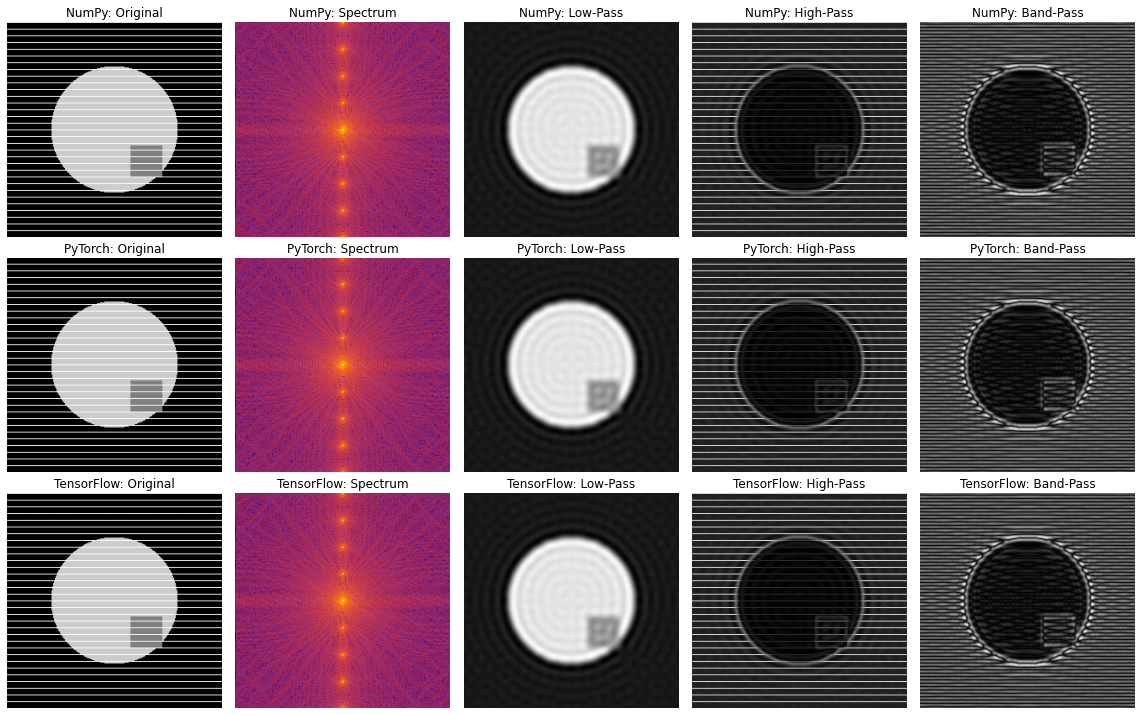

In [5]:
fig, axes = plt.subplots(3, 5, figsize=(16, 10))
rows_data = [
    ("NumPy", np_spec, np_out),
    ("PyTorch", pt_spec, pt_out),
    ("TensorFlow", tf_spec, tf_out)
]

for r, (fw, spec, res) in enumerate(rows_data):
    axes[r, 0].imshow(img, cmap="gray")
    axes[r, 0].set_title(f"{fw}: Original")
    
    axes[r, 1].imshow(spec, cmap="inferno")
    axes[r, 1].set_title(f"{fw}: Spectrum")
    
    for c, k in enumerate(["Low-Pass", "High-Pass", "Band-Pass"], start=2):
        axes[r, c].imshow(res[k], cmap="gray")
        axes[r, c].set_title(f"{fw}: {k}")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()